# 04 — Prédire le décrochage : Cox et gradient boosting, validation 2024 → 2025

**Projet Horizon : décrochage et tutorat** — tâches SV-03 (modèles, validation temporelle) et SV-04 (comparaison et explication).

Ce notebook **ne réentraîne aucun modèle** : il lit les résultats enregistrés par `python run_all.py` dans `data/processed/resultats/` (calculs dans `src/ml_survie.py`). Décisions appliquées : D-42 (activité de la semaine précédente seulement), D-43 (variables de la rentrée, aucune variable de tutorat), D-60 (gradient boosting à temps discret), D-63 (méthode, réglages et mesures).

> Les modèles **prédisent** ; les variables qu'ils utilisent sont **associées** au décrochage. Rien ici ne dit ce qui *cause* le décrochage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

# Le notebook est dans notebooks/ : on remonte jusqu'à la racine du dépôt (dossier qui
# contient src/config.py) pour pouvoir importer src/, quel que soit le dossier de lancement.
racine = Path.cwd()
while not (racine / "src" / "config.py").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))

from src import config, survie

pd.set_option("display.width", 160)
config.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def lire_resultat(nom):
    """Lit un résultat enregistré par run_all.py (data/processed/resultats/)."""
    return pd.read_csv(config.DOSSIER_RESULTATS / nom, sep=config.SEPARATEUR_PROCESSED, encoding=config.ENCODAGE)


def enregistrer(figure, nom):
    """Enregistre une figure en PNG dans docs/figures/ et l'affiche."""
    figure.tight_layout()
    figure.savefig(config.DOSSIER_FIGURES / nom, dpi=120)
    plt.show()


def nombre(x, decimales=1):
    """Nombre au format français, ex. 0,638."""
    return f"{x:.{decimales}f}".replace(".", ",")


def entier(n):
    """Entier avec séparateur des milliers, ex. 60 691."""
    return f"{int(round(n)):,}".replace(",", " ")


COX, GB, REF = "Cox", "Gradient boosting", "Référence (Kaplan-Meier 2024)"
COULEURS = {COX: "#4C72B0", GB: "#DD8452", REF: "#8C8C8C"}

## 1. La question et la règle du jeu

**La question** : à partir de ce que l'on sait d'un étudiant, peut-on prédire s'il va décrocher, et quand ?

**La règle** (validation temporelle) : les modèles apprennent sur la **cohorte 2024** et sont jugés sur la **cohorte 2025**, comme s'ils avaient été construits l'année précédente. Rien de 2025 ne sert à l'apprentissage : ni les valeurs de remplacement des manquants (médianes de 2024), ni la liste des colonnes, ni les réglages. Les réglages du gradient boosting ont été **fixés d'avance** (D-63), sans aucun essai sur 2025.

**Deux modèles « rentrée »**, avec les variables connues à l'inscription (âge, note du bac, distance, genre, bourse, filière, région, emploi) :
- le **modèle de Cox**, déjà présenté dans le notebook 03 ;
- le **gradient boosting à temps discret** : pour chaque étudiant encore inscrit, un ensemble d'arbres de décision estime le risque de décrocher *dans la semaine* (semaine 1, 2, … 30). La courbe de survie s'obtient ensuite en enchaînant les semaines : la probabilité d'être encore là en semaine 3 est (1 − risque de la semaine 1) × (1 − risque de la semaine 2) × (1 − risque de la semaine 3). Contrairement au Cox, il peut capter des effets non linéaires et des combinaisons de variables.

**Un modèle « hebdomadaire »** : le même gradient boosting, avec en plus l'activité de la **semaine précédente** (connexions, devoirs, note, absences, état d'activité). C'est un score qu'on peut actualiser chaque semaine. Il n'utilise jamais la semaine en cours (D-42), qu'on ne connaît pas encore au moment de prédire.

## 2. Les données

In [2]:
donnees = lire_resultat("ml_donnees.csv")
affichage = donnees.rename(columns={"cohorte": "Cohorte", "role": "Rôle", "etudiants": "Étudiants",
                                    "decrochages": "Décrochages", "semaines_etudiants": "Semaines-étudiants",
                                    "decrochages_semaines": "Semaines avec décrochage"}).set_index("Cohorte")
display(affichage)
medianes = lire_resultat("ml_medianes_2024.csv").set_index("variable")["mediane_2024"]
entrainement, test = donnees.iloc[0], donnees.iloc[1]
print(f"Apprentissage : {entier(entrainement['etudiants'])} étudiants de 2024, dont {entier(entrainement['decrochages'])} "
      f"décrochages ({nombre(100 * entrainement['decrochages'] / entrainement['etudiants'])} %), soit "
      f"{entier(entrainement['semaines_etudiants'])} semaines-étudiants pour le gradient boosting. Test : "
      f"{entier(test['etudiants'])} étudiants de 2025, dont {entier(test['decrochages'])} décrochages "
      f"({nombre(100 * test['decrochages'] / test['etudiants'])} %).")
print(f"Valeurs manquantes de 2025 remplacées par les médianes de 2024 : âge {nombre(medianes['age'])}, note du bac "
      f"{nombre(medianes['note_bac'], 2)}, log2 de la distance {nombre(medianes['log2_distance'], 3)}.")

,Rôle,Étudiants,Décrochages,Semaines-étudiants,Semaines avec décrochage
Cohorte,,,,,
2024,entraînement,2495,715,60691,715
2025,test,2505,725,61247,725


Apprentissage : 2 495 étudiants de 2024, dont 715 décrochages (28,7 %), soit 60 691 semaines-étudiants pour le gradient boosting. Test : 2 505 étudiants de 2025, dont 725 décrochages (28,9 %).
Valeurs manquantes de 2025 remplacées par les médianes de 2024 : âge 20,0, note du bac 12,31, log2 de la distance 3,293.


## 3. Le modèle « rentrée » : qui fait le mieux sur 2025 ?

Trois mesures, toutes calculées sur les étudiants de 2025 :
- **C-index** : la probabilité que, de deux étudiants, celui qui décroche le plus tôt ait le risque prédit le plus élevé (0,5 = hasard, 1 = classement parfait) ;
- **Brier score intégré** : l'erreur moyenne de la probabilité prédite d'être encore là, semaine après semaine (0 = parfait ; plus c'est bas, mieux c'est) ; la censure est prise en compte par pondération ;
- **écart de calibration à 20 semaines** : l'écart moyen entre le risque prédit et le risque observé dans 10 groupes d'étudiants (0 = prédictions fidèles).

La **référence** donne à tout le monde la même courbe (Kaplan-Meier de 2024) : un modèle utile doit faire mieux qu'elle.

In [3]:
mesures = lire_resultat("ml_mesures_rentree.csv").set_index("modele")
display(mesures.rename(columns={"c_index": "C-index", "brier_integre": "Brier intégré",
                                "brier_20_semaines": "Brier à 20 semaines",
                                "ecart_calibration": "Écart de calibration à 20 sem."}).round(4))
cox, gb, ref = mesures.loc[COX], mesures.loc[GB], mesures.loc[REF]
meilleur_c = COX if cox["c_index"] > gb["c_index"] else GB
print(f"C-index : Cox {nombre(cox['c_index'], 3)}, gradient boosting {nombre(gb['c_index'], 3)} (hasard : 0,5). "
      f"Le {meilleur_c} classe le mieux les étudiants : pour deux étudiants pris au hasard, il désigne le bon "
      f"(celui qui décroche le plus tôt) dans environ {nombre(100 * max(cox['c_index'], gb['c_index']), 0)} % des cas.")
gain_cox = 100 * (1 - cox["brier_integre"] / ref["brier_integre"])
gain_gb = 100 * (1 - gb["brier_integre"] / ref["brier_integre"])
print(f"Brier intégré : Cox {nombre(cox['brier_integre'], 4)}, gradient boosting {nombre(gb['brier_integre'], 4)}, "
      f"référence {nombre(ref['brier_integre'], 4)} : le Cox réduit l'erreur de {nombre(gain_cox)} % par rapport à la "
      f"référence, le gradient boosting de {nombre(gain_gb)} %. Les variables de la rentrée apportent donc une "
      "information réelle mais limitée : beaucoup de ce qui fait décrocher n'est pas connu à l'inscription.")
print(f"Calibration à 20 semaines : écart moyen de {nombre(100 * cox['ecart_calibration'])} points pour le Cox, "
      f"{nombre(100 * gb['ecart_calibration'])} points pour le gradient boosting.")
if cox["c_index"] > gb["c_index"] and cox["brier_integre"] < gb["brier_integre"]:
    print("Sur les trois mesures, le Cox fait mieux que le gradient boosting avec les réglages fixés d'avance : "
          "c'est un résultat, rapporté tel quel (D-63). Une explication possible : avec peu de variables, toutes connues "
          "à la rentrée, la forme simple du Cox suffit, et la souplesse du gradient boosting l'expose davantage au "
          "sur-apprentissage (voir sa calibration ci-dessous).")

,C-index,Brier intégré,Brier à 20 semaines,Écart de calibration à 20 sem.
modele,,,,
Cox,0.6382,0.1332,0.1740,0.0283
Gradient boosting,0.6100,0.1401,0.1838,0.0590
Référence (Kaplan-Meier 2024),0.5000,0.1410,0.1857,NaN


C-index : Cox 0,638, gradient boosting 0,610 (hasard : 0,5). Le Cox classe le mieux les étudiants : pour deux étudiants pris au hasard, il désigne le bon (celui qui décroche le plus tôt) dans environ 64 % des cas.
Brier intégré : Cox 0,1332, gradient boosting 0,1401, référence 0,1410 : le Cox réduit l'erreur de 5,5 % par rapport à la référence, le gradient boosting de 0,6 %. Les variables de la rentrée apportent donc une information réelle mais limitée : beaucoup de ce qui fait décrocher n'est pas connu à l'inscription.
Calibration à 20 semaines : écart moyen de 2,8 points pour le Cox, 5,9 points pour le gradient boosting.
Sur les trois mesures, le Cox fait mieux que le gradient boosting avec les réglages fixés d'avance : c'est un résultat, rapporté tel quel (D-63). Une explication possible : avec peu de variables, toutes connues à la rentrée, la forme simple du Cox suffit, et la souplesse du gradient boosting l'expose davantage au sur-apprentissage (voir sa calibration ci-dessous).


In [4]:
hr = lire_resultat("ml_hr_cox_2024.csv").set_index("variable")
LIBELLES = {
    "age": "Âge (par année)", "note_bac": "Note du bac (par point)", "log2_distance": "Distance au campus (par doublement)",
    "age_variable": "Âge", "note_bac_variable": "Note du bac", "log2_distance_variable": "Distance au campus",
    "genre": "Genre", "boursier": "Boursier", "filiere": "Filière", "region_dakar": "Région d'origine",
    "emploi_parallele": "Emploi en parallèle",
    "nb_connexions_lms_prec": "Connexions LMS, semaine précédente", "devoirs_rendus_prec": "Devoirs rendus, semaine précédente",
    "note_moyenne_prec": "Note moyenne, semaine précédente", "absences_prec": "Absences, semaine précédente",
    "etat_activite_prec": "État d'activité, semaine précédente",
}


def libelle_hr(colonne):
    """Texte lisible d'une colonne du Cox (ex. « Filière : Droit (réf. Informatique) »)."""
    if colonne in LIBELLES:
        return LIBELLES[colonne]
    variable, modalite = colonne.split(config.SEPARATEUR_INDICATRICE)
    return f"{LIBELLES[variable]} : {modalite} (réf. {config.REFERENCES_COX[variable]})"


tableau_hr = hr.copy()
tableau_hr.index = [libelle_hr(c) for c in hr.index]
display(tableau_hr.round(3))
nets = hr[hr["p"] < config.ALPHA]
print("Associés, dans le Cox appris sur 2024, à un risque de décrochage plus élevé (p < 0,05) : "
      + " ; ".join(f"{libelle_hr(c)} HR {nombre(v, 2)}" for c, v in nets["HR"].items() if v > 1) + ".")
print("Associés à un risque plus faible : "
      + " ; ".join(f"{libelle_hr(c)} HR {nombre(v, 2)}" for c, v in nets["HR"].items() if v < 1) + ".")
print("Ces associations sont proches de celles du Cox sur les deux cohortes (notebook 03) : elles sont stables d'une "
      "année à l'autre, ce qui rend la prédiction possible.")

schoenfeld = lire_resultat("ml_schoenfeld_cox_2024.csv")
violations = schoenfeld[schoenfeld["p"] < config.ALPHA]
if len(violations):
    print(f"Test de Schoenfeld (pour information) : {len(violations)} colonne(s) sous 0,05 : "
          + ", ".join(f"{libelle_hr(c)} (p = {nombre(p, 3)})" for c, p in zip(violations['colonne'], violations['p']))
          + ". L'association de cette variable avec le risque varie un peu au fil des semaines ; le modèle n'est pas "
          "modifié (il sert ici à prédire, pas à interpréter finement), mais la limite est notée.")
else:
    print(f"Test de Schoenfeld : aucune colonne sous 0,05 (p minimum {nombre(schoenfeld['p'].min(), 3)}).")

,HR,IC bas,IC haut,p
Âge (par année),1.098,1.051,1.148,0.000
Note du bac (par point),0.836,0.801,0.871,0.000
Distance au campus (par doublement),1.126,1.064,1.192,0.000
Genre : M (réf. F),1.106,0.954,1.282,0.182
Boursier : Oui (réf. Non),0.732,0.628,0.854,0.000
Filière : Gestion (réf. Informatique),0.845,0.689,1.036,0.105
Filière : Droit (réf. Informatique),1.015,0.815,1.264,0.893
Filière : Génie civil (réf. Informatique),0.838,0.660,1.063,0.145
Filière : Communication (réf. Informatique),0.886,0.702,1.118,0.306
Région d'origine : Hors Dakar (réf. Dakar),1.020,0.861,1.208,0.820


Associés, dans le Cox appris sur 2024, à un risque de décrochage plus élevé (p < 0,05) : Âge (par année) HR 1,10 ; Distance au campus (par doublement) HR 1,13 ; Emploi en parallèle : Oui (réf. Non) HR 1,72.
Associés à un risque plus faible : Note du bac (par point) HR 0,84 ; Boursier : Oui (réf. Non) HR 0,73.
Ces associations sont proches de celles du Cox sur les deux cohortes (notebook 03) : elles sont stables d'une année à l'autre, ce qui rend la prédiction possible.
Test de Schoenfeld (pour information) : 1 colonne(s) sous 0,05 : Emploi en parallèle : Oui (réf. Non) (p = 0,030). L'association de cette variable avec le risque varie un peu au fil des semaines ; le modèle n'est pas modifié (il sert ici à prédire, pas à interpréter finement), mais la limite est notée.


## 4. Calibration à 20 semaines

Les étudiants de 2025 sont rangés en 10 groupes de même taille selon leur risque prédit de décrocher avant 20 semaines. Pour chaque groupe, on compare le risque prédit moyen au risque observé (Kaplan-Meier du groupe). Des points sur la diagonale signifient des prédictions fidèles.

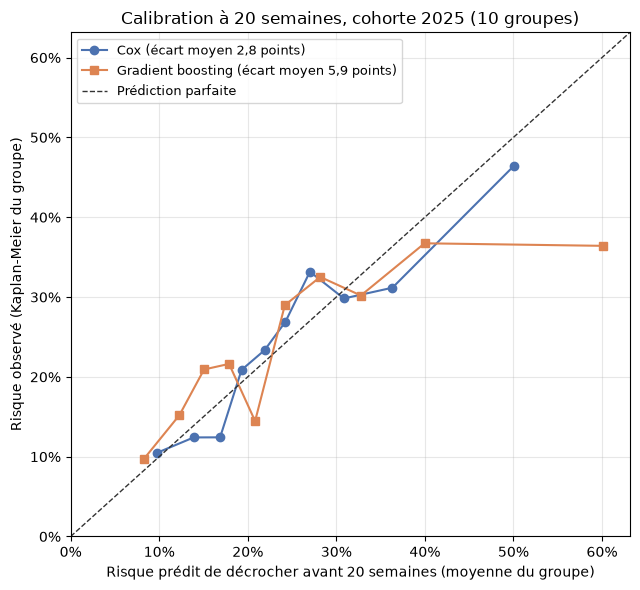

Cox : dans le groupe le moins à risque, 9,8 % prédit contre 10,5 % observé ; dans le groupe le plus à risque, 50,0 % prédit contre 46,4 % observé.
Gradient boosting : dans le groupe le moins à risque, 8,3 % prédit contre 9,7 % observé ; dans le groupe le plus à risque, 60,2 % prédit contre 36,4 % observé.
Le gradient boosting surestime nettement le risque des étudiants qu'il juge les plus fragiles : ses prédictions extrêmes sont trop confiantes. Celles du Cox restent plus proches de ce qui est observé.


In [5]:
calibration = lire_resultat("ml_calibration_20_semaines.csv")
figure, axe = plt.subplots(figsize=(6.5, 6))
for modele, marqueur in [(COX, "o"), (GB, "s")]:
    groupe = calibration[calibration["modele"] == modele]
    axe.plot(groupe["risque_predit"], groupe["risque_observe"], marker=marqueur, color=COULEURS[modele],
             label=f"{modele} (écart moyen {nombre(100 * mesures.loc[modele, 'ecart_calibration'])} points)")
limite = max(calibration["risque_predit"].max(), calibration["risque_observe"].max()) * 1.05
axe.plot([0, limite], [0, limite], color="#333333", linestyle="--", linewidth=1, label="Prédiction parfaite")
axe.set_xlim(0, limite)
axe.set_ylim(0, limite)
axe.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axe.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axe.set_xlabel("Risque prédit de décrocher avant 20 semaines (moyenne du groupe)")
axe.set_ylabel("Risque observé (Kaplan-Meier du groupe)")
axe.set_title("Calibration à 20 semaines, cohorte 2025 (10 groupes)")
axe.legend(loc="upper left", fontsize=9)
axe.grid(alpha=0.3)
enregistrer(figure, "04_calibration_20_semaines.png")

for modele in (COX, GB):
    groupe = calibration[calibration["modele"] == modele].set_index("groupe")
    bas, haut = groupe.iloc[0], groupe.iloc[-1]
    print(f"{modele} : dans le groupe le moins à risque, {nombre(100 * bas['risque_predit'])} % prédit contre "
          f"{nombre(100 * bas['risque_observe'])} % observé ; dans le groupe le plus à risque, "
          f"{nombre(100 * haut['risque_predit'])} % prédit contre {nombre(100 * haut['risque_observe'])} % observé.")
print("Le gradient boosting surestime nettement le risque des étudiants qu'il juge les plus fragiles : ses prédictions "
      "extrêmes sont trop confiantes. Celles du Cox restent plus proches de ce qui est observé."
      if (calibration.query("modele == @GB").iloc[-1]["risque_predit"] - calibration.query("modele == @GB").iloc[-1]["risque_observe"])
      > (calibration.query("modele == @COX").iloc[-1]["risque_predit"] - calibration.query("modele == @COX").iloc[-1]["risque_observe"])
      else "Les deux modèles restent proches de la diagonale dans les groupes extrêmes.")

## 5. Le Brier score semaine par semaine

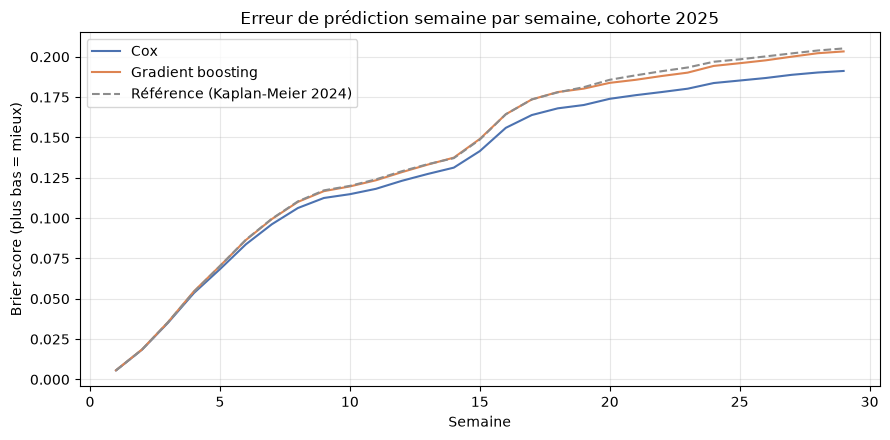

L'erreur grandit au fil des semaines, à mesure que les décrochages s'accumulent (maximum du Cox en semaine 29 : 0,191).
Le Cox est sous la référence 29 semaines sur 29 ; le gradient boosting seulement 21 sur 29, et sous le Cox 0 semaine(s) sur 29. L'avantage du Cox est faible semaine par semaine, mais régulier.


In [6]:
brier = lire_resultat("ml_brier_par_semaine.csv").set_index("semaine")
figure, axe = plt.subplots(figsize=(9, 4.5))
for modele in (COX, GB, REF):
    axe.plot(brier.index, brier[modele], color=COULEURS[modele], label=modele,
             linestyle="--" if modele == REF else "-")
axe.set_xlabel("Semaine")
axe.set_ylabel("Brier score (plus bas = mieux)")
axe.set_title("Erreur de prédiction semaine par semaine, cohorte 2025")
axe.legend()
axe.grid(alpha=0.3)
enregistrer(figure, "04_brier_par_semaine.png")
semaine_max = int(brier[COX].idxmax())
nb_semaines = len(brier)
cox_sous_ref = int((brier[COX] < brier[REF]).sum())
gb_sous_ref = int((brier[GB] < brier[REF]).sum())
gb_sous_cox = int((brier[GB] < brier[COX]).sum())
print(f"L'erreur grandit au fil des semaines, à mesure que les décrochages s'accumulent (maximum du Cox en semaine "
      f"{semaine_max} : {nombre(brier[COX].max(), 3)}).")
print(f"Le Cox est sous la référence {cox_sous_ref} semaines sur {nb_semaines} ; le gradient boosting seulement "
      f"{gb_sous_ref} sur {nb_semaines}, et sous le Cox {gb_sous_cox} semaine(s) sur {nb_semaines}. L'avantage du Cox est "
      "faible semaine par semaine, mais régulier.")

## 6. Courbe moyenne prédite contre courbe observée en 2025

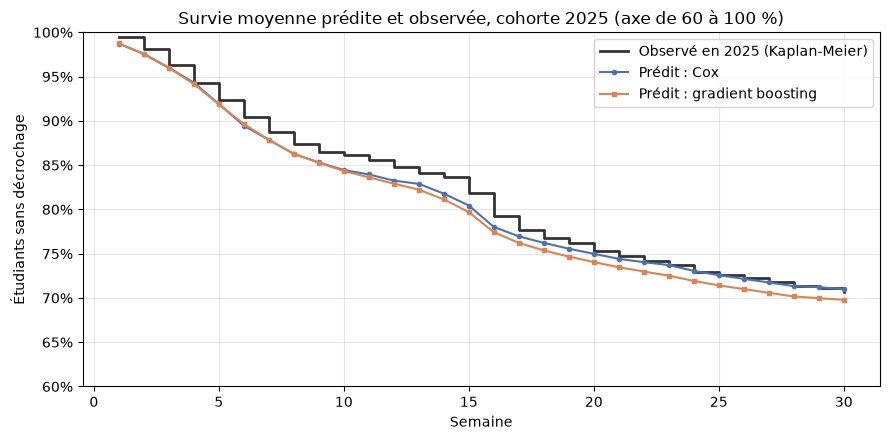

Observé en 2025 : 24,7 % des étudiants ont décroché avant 20 semaines, 29,3 % avant 30 semaines. Prédit en moyenne : Cox 29,0 %, gradient boosting 30,2 % à 30 semaines. Les deux modèles retrouvent bien le niveau global de décrochage de la nouvelle cohorte.


In [7]:
predictions = lire_resultat("ml_predictions_2025.csv")
moyennes = predictions.groupby("semaine")[["survie_cox", "survie_gradient_boosting"]].mean()
base = survie.lire_base()
base_2025 = base[base[config.VARIABLE_COHORTE].astype(int) == config.COHORTE_TEST]
kmf_2025 = survie.ajuster_kaplan_meier(base_2025["T"], base_2025["E"], nom="Observé 2025")
observee = kmf_2025.survival_function_at_times(moyennes.index)

figure, axe = plt.subplots(figsize=(9, 4.5))
axe.step(moyennes.index, observee.to_numpy(), where="post", color="#333333", linewidth=2,
         label="Observé en 2025 (Kaplan-Meier)")
axe.plot(moyennes.index, moyennes["survie_cox"], color=COULEURS[COX], marker="o", markersize=3, label="Prédit : Cox")
axe.plot(moyennes.index, moyennes["survie_gradient_boosting"], color=COULEURS[GB], marker="s", markersize=3,
         label="Prédit : gradient boosting")
axe.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axe.set_ylim(0.6, 1.0)
axe.set_xlabel("Semaine")
axe.set_ylabel("Étudiants sans décrochage")
axe.set_title("Survie moyenne prédite et observée, cohorte 2025 (axe de 60 à 100 %)")
axe.legend()
axe.grid(alpha=0.3)
enregistrer(figure, "04_survie_moyenne_2025.png")
s20 = observee.loc[config.SEMAINE_CALIBRATION]
s30 = observee.loc[config.N_SEMAINES]
print(f"Observé en 2025 : {nombre(100 * (1 - s20))} % des étudiants ont décroché avant {config.SEMAINE_CALIBRATION} semaines, "
      f"{nombre(100 * (1 - s30))} % avant {config.N_SEMAINES} semaines. Prédit en moyenne : Cox "
      f"{nombre(100 * (1 - moyennes.loc[config.N_SEMAINES, 'survie_cox']))} %, gradient boosting "
      f"{nombre(100 * (1 - moyennes.loc[config.N_SEMAINES, 'survie_gradient_boosting']))} % à {config.N_SEMAINES} semaines. "
      "Les deux modèles retrouvent bien le niveau global de décrochage de la nouvelle cohorte.")

## 7. Le score hebdomadaire

Ici, on juge chaque **semaine-étudiant** de 2025 : le modèle donne un risque de décrocher cette semaine-là, et l'on regarde si l'étudiant a effectivement décroché. L'**AUC** est la probabilité qu'une semaine avec décrochage reçoive un risque plus élevé qu'une semaine sans décrochage (0,5 = hasard).

In [8]:
hebdo = lire_resultat("ml_score_hebdomadaire.csv").set_index("modele")
display(hebdo.rename(columns={"auc": "AUC hebdomadaire", "decrochages_attendus": "Décrochages attendus",
                              "decrochages_observes": "Décrochages observés"}).round(3))
auc = hebdo["auc"]
ligne_hebdo = hebdo.loc["Gradient boosting hebdomadaire"]
print(f"AUC hebdomadaire : Cox {nombre(auc['Cox'], 3)}, gradient boosting « rentrée » "
      f"{nombre(auc['Gradient boosting « rentrée »'], 3)}, gradient boosting hebdomadaire "
      f"{nombre(auc['Gradient boosting hebdomadaire'], 3)}.")
print(f"Ajouter l'activité de la semaine précédente fait passer le gradient boosting de "
      f"{nombre(auc['Gradient boosting « rentrée »'], 3)} à {nombre(auc['Gradient boosting hebdomadaire'], 3)} : "
      "les signaux récents (absences, connexions, notes) aident à repérer la semaine où un étudiant décroche. "
      + ("Le score hebdomadaire atteint ainsi le niveau du Cox, sans le dépasser nettement."
         if abs(auc["Gradient boosting hebdomadaire"] - auc["Cox"]) < 0.01 else ""))
print(f"Sur l'année 2025, le modèle hebdomadaire attendait {entier(ligne_hebdo['decrochages_attendus'])} décrochages ; "
      f"{entier(ligne_hebdo['decrochages_observes'])} ont été observés (écart de "
      f"{nombre(100 * (ligne_hebdo['decrochages_attendus'] / ligne_hebdo['decrochages_observes'] - 1))} %) : le niveau "
      "global du risque est bien estimé.")

,AUC hebdomadaire,Décrochages attendus,Décrochages observés
modele,,,
Cox,0.688,NaN,NaN
Gradient boosting « rentrée »,0.658,NaN,NaN
Gradient boosting hebdomadaire,0.685,748.966,725.0


AUC hebdomadaire : Cox 0,688, gradient boosting « rentrée » 0,658, gradient boosting hebdomadaire 0,685.
Ajouter l'activité de la semaine précédente fait passer le gradient boosting de 0,658 à 0,685 : les signaux récents (absences, connexions, notes) aident à repérer la semaine où un étudiant décroche. Le score hebdomadaire atteint ainsi le niveau du Cox, sans le dépasser nettement.
Sur l'année 2025, le modèle hebdomadaire attendait 749 décrochages ; 725 ont été observés (écart de 3,3 %) : le niveau global du risque est bien estimé.


## 8. Expliquer les modèles : importance par permutation

Pour mesurer ce qu'une variable apporte, on la **mélange** au hasard entre les étudiants de 2025 (10 fois, graine fixée) et on regarde de combien la performance baisse. Une baisse nulle signifie que le modèle n'en a pas besoin. Pour une variable à plusieurs modalités (filière, région…), toutes ses colonnes sont mélangées ensemble. Ces importances disent ce dont le **modèle** se sert pour prédire ; elles ne disent pas ce qui cause le décrochage.

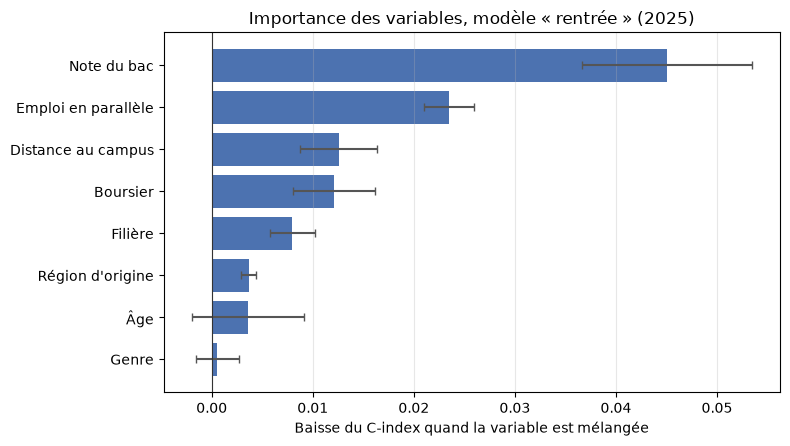

Modèle « rentrée » : les variables dont il se sert le plus sont note du bac (baisse du C-index 0,045), emploi en parallèle (baisse du C-index 0,023), distance au campus (baisse du C-index 0,013). Le genre n'apporte presque rien (0,001).
C'est cohérent avec le Cox : HR de 0,84 par point de note du bac, 1,72 pour un emploi en parallèle, 1,13 par doublement de la distance, et un genre sans association nette (p = 0,18).


In [9]:
importance = lire_resultat("ml_importance.csv")


def nom_variable(v):
    """Nom lisible d'une variable, sans unité (ex. « Note du bac »)."""
    return LIBELLES.get(f"{v}_variable", LIBELLES.get(v, v))


def minuscule(texte):
    """Première lettre en minuscule seulement (garde « LMS » intact)."""
    return texte[0].lower() + texte[1:]


def figure_importance(modele, titre, axe_x, nom_fichier):
    """Barres horizontales : baisse moyenne de la performance et son écart-type."""
    table = importance[importance["modele"] == modele].sort_values("baisse_moyenne")
    figure, axe = plt.subplots(figsize=(8, 0.42 * len(table) + 1.2))
    axe.barh([nom_variable(v) for v in table["variable"]], table["baisse_moyenne"], xerr=table["ecart_type"], color="#4C72B0", ecolor="#555555", capsize=3)
    axe.axvline(0, color="#333333", linewidth=0.8)
    axe.set_xlabel(axe_x)
    axe.set_title(titre)
    axe.grid(axis="x", alpha=0.3)
    enregistrer(figure, nom_fichier)
    return table.sort_values("baisse_moyenne", ascending=False)


rentree = figure_importance("rentree", "Importance des variables, modèle « rentrée » (2025)",
                            "Baisse du C-index quand la variable est mélangée", "04_importance_rentree.png")



premieres = rentree.head(3)
print("Modèle « rentrée » : les variables dont il se sert le plus sont "
      + ", ".join(f"{minuscule(nom_variable(v))} (baisse du C-index {nombre(b, 3)})"
                  for v, b in zip(premieres["variable"], premieres["baisse_moyenne"]))
      + f". Le genre n'apporte presque rien ({nombre(rentree.set_index('variable').loc['genre', 'baisse_moyenne'], 3)}).")
print(f"C'est cohérent avec le Cox : HR de {nombre(hr.loc['note_bac', 'HR'], 2)} par point de note du bac, "
      f"{nombre(hr.loc['emploi_parallele=Oui', 'HR'], 2)} pour un emploi en parallèle, "
      f"{nombre(hr.loc['log2_distance', 'HR'], 2)} par doublement de la distance, et un genre sans association nette "
      f"(p = {nombre(hr.loc['genre=M', 'p'], 2)}).")

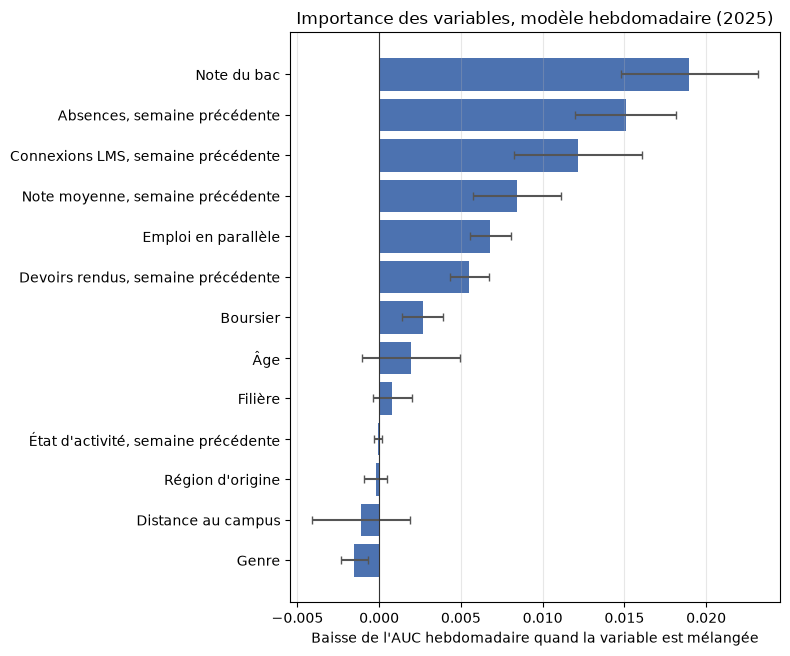

Modèle hebdomadaire : les variables les plus utiles sont note du bac (0,019) ; absences, semaine précédente (0,015) ; connexions LMS, semaine précédente (0,012) ; note moyenne, semaine précédente (0,008).
4 des 5 variables d'activité de la semaine précédente comptent (baisse > 0,002) : absences, semaine précédente ; connexions LMS, semaine précédente ; note moyenne, semaine précédente ; devoirs rendus, semaine précédente. Ces signaux récents complètent les informations de la rentrée.
Variables dont le modèle hebdomadaire n'a presque pas besoin (baisse ≤ 0,002) : âge ; filière ; état d'activité, semaine précédente ; région d'origine ; distance au campus ; genre. Une baisse légèrement négative veut seulement dire que le mélange n'a rien changé (variations dues au hasard).


In [10]:
hebdomadaire = figure_importance("hebdomadaire", "Importance des variables, modèle hebdomadaire (2025)",
                                 "Baisse de l'AUC hebdomadaire quand la variable est mélangée",
                                 "04_importance_hebdomadaire.png")
premieres = hebdomadaire.head(4)
activite = hebdomadaire[hebdomadaire["variable"].str.endswith(config.SUFFIXE_PREC)]
print("Modèle hebdomadaire : les variables les plus utiles sont "
      + " ; ".join(f"{minuscule(nom_variable(v))} ({nombre(b, 3)})"
                  for v, b in zip(premieres["variable"], premieres["baisse_moyenne"])) + ".")
activite_utile = activite[activite["baisse_moyenne"] > 0.002]
print(f"{len(activite_utile)} des {len(activite)} variables d'activité de la semaine précédente comptent (baisse > 0,002) : "
      + " ; ".join(minuscule(nom_variable(v)) for v in activite_utile["variable"])
      + ". Ces signaux récents complètent les informations de la rentrée.")
negligeables = hebdomadaire[hebdomadaire["baisse_moyenne"].abs() <= 0.002]["variable"]
print("Variables dont le modèle hebdomadaire n'a presque pas besoin (baisse ≤ 0,002) : "
      + " ; ".join(minuscule(nom_variable(v)) for v in negligeables)
      + ". Une baisse légèrement négative veut seulement dire que le mélange n'a rien changé (variations dues au hasard).")

## 9. Conclusion

In [11]:
print(f"Modèle « rentrée » : le Cox fait mieux que le gradient boosting sur les trois mesures de 2025 "
      f"(C-index {nombre(cox['c_index'], 3)} contre {nombre(gb['c_index'], 3)} ; Brier intégré {nombre(cox['brier_integre'], 4)} "
      f"contre {nombre(gb['brier_integre'], 4)} ; écart de calibration {nombre(100 * cox['ecart_calibration'])} contre "
      f"{nombre(100 * gb['ecart_calibration'])} points), et tous deux font mieux que la référence."
      if cox["c_index"] > gb["c_index"] and cox["brier_integre"] < gb["brier_integre"]
      and cox["ecart_calibration"] < gb["ecart_calibration"] else
      "Modèle « rentrée » : aucun des deux modèles ne l'emporte sur les trois mesures (voir le tableau de la section 3).")
print(f"Score hebdomadaire : l'activité de la semaine précédente améliore le gradient boosting (AUC "
      f"{nombre(auc['Gradient boosting « rentrée »'], 3)} → {nombre(auc['Gradient boosting hebdomadaire'], 3)}) ; il prédit "
      f"bien le nombre total de décrochages ({entier(ligne_hebdo['decrochages_attendus'])} attendus pour "
      f"{entier(ligne_hebdo['decrochages_observes'])} observés).")

Modèle « rentrée » : le Cox fait mieux que le gradient boosting sur les trois mesures de 2025 (C-index 0,638 contre 0,610 ; Brier intégré 0,1332 contre 0,1401 ; écart de calibration 2,8 contre 5,9 points), et tous deux font mieux que la référence.
Score hebdomadaire : l'activité de la semaine précédente améliore le gradient boosting (AUC 0,658 → 0,685) ; il prédit bien le nombre total de décrochages (749 attendus pour 725 observés).


**Limites** :
- les réglages du gradient boosting sont ceux fixés d'avance (D-63), **non optimisés** : un réglage fin aurait pu l'améliorer, mais il aurait fallu le faire sans toucher à 2025 (par exemple par validation croisée sur 2024) ;
- une **seule cohorte de test** : les mesures ont leur propre incertitude, qui n'est pas chiffrée ici ;
- le pouvoir prédictif reste modéré (C-index autour de 0,64) : à la rentrée, on ne connaît qu'une petite partie de ce qui fait décrocher ;
- le Cox appris sur 2024 donne p = 0,030 pour l'emploi en parallèle au test de Schoenfeld ; non corrigé (D-64), car 13 colonnes sont testées à la fois (seuil de Bonferroni 0,05 / 13 ≈ 0,0038, non franchi), aucune violation n'apparaît sur les 5 000 étudiants stratifiés par cohorte (SV-02, p minimum 0,36), et ce Cox sert à prédire : sa calibration est mesurée directement sur 2025 (écart de 2,8 points) ; le modifier après avoir vu 2025 reviendrait à l'ajuster au jeu de test.

Les fiches d'alerte utilisent le Cox (risque et facteurs, D-66) ; le tableau de bord affichera aussi le score hebdomadaire du gradient boosting (DB-01).